In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lokasi proyek
PROJECT_DIR = Path.cwd()

# Cari dataset di seluruh subfolder proyek
train_files = list(PROJECT_DIR.rglob("interactions_train.csv"))
item_files = list(PROJECT_DIR.rglob("items.csv"))

print("File training ditemukan:", train_files)
print("File items ditemukan:", item_files)

if not train_files or not item_files:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Periksa folder hasil ekstraksi."
    )

# Membaca dataset
train = pd.read_csv(train_files[0])
items = pd.read_csv(item_files[0])

print("\nUkuran training:", train.shape)
print("Ukuran metadata item:", items.shape)

print("\nLima baris pertama training:")
display(train.head())

File training ditemukan: [WindowsPath('d:/Semester 7/Sisrek/Praktikum/proyek/MAIN DATA-20261010T150234Z-1-001/MAIN DATA/interactions_train.csv')]
File items ditemukan: [WindowsPath('d:/Semester 7/Sisrek/Praktikum/proyek/MAIN DATA-20261010T150234Z-1-001/MAIN DATA/items.csv')]

Ukuran training: (427957, 4)
Ukuran metadata item: (23582, 8)

Lima baris pertama training:


,user_id,item_id,rating,timestamp
0,AFRGJMSUHGKN6E36WF7NUXIQVXVQ,B07YM5ZHS9,4.0,1053991604000
1,AE4H7ZEPV4JIYCPBM23XHY57FHGQ,0634031600,5.0,1058971915000
2,AFJWPVVW4BE435ILB7TOM4PQZHEA,B0002GO864,4.0,1091480547000
3,AGFVP2RIKQMCJOWPEFL2YOQKSUGA,B071GLQQTW,5.0,1092714535000
4,AGFVP2RIKQMCJOWPEFL2YOQKSUGA,B0002F79E8,5.0,1093033600000


In [5]:
# Identifikasi seluruh CSV dataset SISREK

csv_files = sorted([
    file for file in PROJECT_DIR.rglob("*.csv")
    if any(
        folder in str(file).upper()
        for folder in ["MAIN DATA", "MAIN_DATA",
                       "SUPPORTING DATA", "SUPPORTING_DATA"]
    )
])

summary = []

for file in csv_files:
    df = pd.read_csv(file)

    summary.append({
        "Nama File": file.name,
        "Jumlah Baris": df.shape[0],
        "Jumlah Kolom": df.shape[1],
        "Nama Kolom": ", ".join(df.columns)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)
print("Total CSV ditemukan:", len(summary_df))

,Nama File,Jumlah Baris,Jumlah Kolom,Nama Kolom
0,candidate_items_warm.csv,22753,1,item_id
1,interactions_train.csv,427957,4,"user_id, item_id, rating, timestamp"
2,interactions_validation.csv,41284,4,"user_id, item_id, rating, timestamp"
3,items.csv,23582,8,"item_id, title, main_category, store, categori..."
4,evaluable_users_validation_warm.csv,11659,1,user_id
5,interactions_validation_cold_item.csv,4271,4,"user_id, item_id, rating, timestamp"
6,interactions_validation_warm.csv,30360,4,"user_id, item_id, rating, timestamp"
7,item_activity_train.csv,22753,5,"item_id, train_interactions, train_unique_user..."
8,user_activity_train.csv,54483,5,"user_id, train_interactions, train_unique_item..."


Total CSV ditemukan: 9


In [6]:
# 1.2 Statistik Dasar Dataset Training

print("=== STATISTIK DASAR TRAINING ===")

print("Jumlah interaksi:", len(train))
print("Jumlah user unik:", train["user_id"].nunique())
print("Jumlah item unik:", train["item_id"].nunique())

print("\nRata-rata interaksi per user:")
print(round(len(train) / train["user_id"].nunique(), 2))

print("\nMissing Values:")
print(train.isnull().sum())

print("\nJumlah baris duplikat:")
print(train.duplicated().sum())

print("\nTipe data setiap kolom:")
print(train.dtypes)

=== STATISTIK DASAR TRAINING ===
Jumlah interaksi: 427957
Jumlah user unik: 54483
Jumlah item unik: 22753

Rata-rata interaksi per user:
7.85

Missing Values:
user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64

Jumlah baris duplikat:
0

Tipe data setiap kolom:
user_id          str
item_id          str
rating       float64
timestamp      int64
dtype: object


,Jumlah Interaksi,Persentase (%)
rating,,
1.0,17486,4.09
2.0,14335,3.35
3.0,28578,6.68
4.0,64120,14.98
5.0,303438,70.90


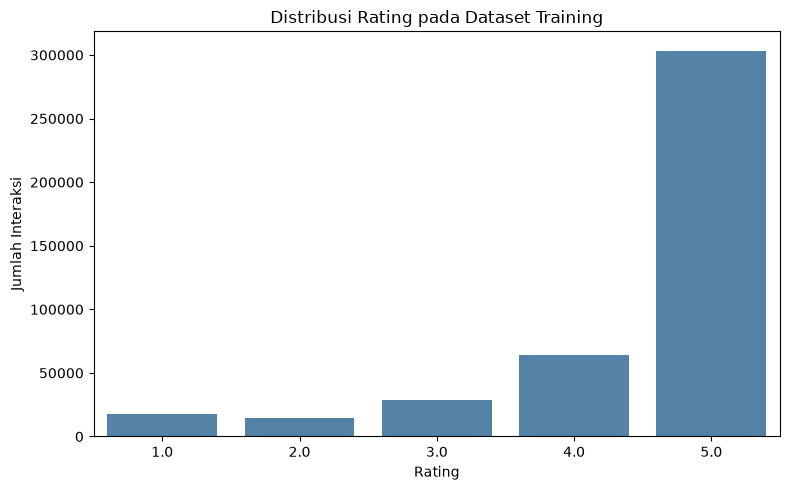

In [7]:
# 1.3 Analisis Distribusi Rating

rating_count = train["rating"].value_counts().sort_index()
rating_percentage = train["rating"].value_counts(
    normalize=True
).sort_index() * 100

rating_summary = pd.DataFrame({
    "Jumlah Interaksi": rating_count,
    "Persentase (%)": rating_percentage.round(2)
})

display(rating_summary)

# Visualisasi distribusi rating
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_count.index,
    y=rating_count.values,
    color="steelblue"
)

plt.title("Distribusi Rating pada Dataset Training")
plt.xlabel("Rating")
plt.ylabel("Jumlah Interaksi")
plt.tight_layout()
plt.show()

In [8]:
# 1.4 Pemeriksaan kualitas seluruh CSV

quality_results = []

for file in csv_files:
    df = pd.read_csv(file)

    quality_results.append({
        "Nama File": file.name,
        "Jumlah Baris": len(df),
        "Jumlah Kolom": len(df.columns),
        "Missing Values": df.isnull().sum().sum(),
        "Baris Duplikat": df.duplicated().sum()
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

,Nama File,Jumlah Baris,Jumlah Kolom,Missing Values,Baris Duplikat
0,candidate_items_warm.csv,22753,1,0,0
1,interactions_train.csv,427957,4,0,0
2,interactions_validation.csv,41284,4,0,0
3,items.csv,23582,8,231,0
4,evaluable_users_validation_warm.csv,11659,1,0,0
5,interactions_validation_cold_item.csv,4271,4,0,0
6,interactions_validation_warm.csv,30360,4,0,0
7,item_activity_train.csv,22753,5,0,0
8,user_activity_train.csv,54483,5,0,0


In [9]:
# 1.5 Analisis Rentang Waktu Interaksi

# Konversi timestamp (milidetik) menjadi tanggal
train["datetime"] = pd.to_datetime(
    train["timestamp"],
    unit="ms",
    utc=True
)

print("Tanggal interaksi paling awal:", train["datetime"].min())
print("Tanggal interaksi paling akhir:", train["datetime"].max())

print("\nJumlah interaksi per tahun:")
display(
    train["datetime"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_frame("Jumlah Interaksi")
)

Tanggal interaksi paling awal: 2003-05-26 23:26:44+00:00
Tanggal interaksi paling akhir: 2021-08-11 00:51:30.562000+00:00

Jumlah interaksi per tahun:


,Jumlah Interaksi
datetime,
2003,2
2004,25
2005,22
2006,60
2007,131
2008,262
2009,620
2010,1907
2011,4665


In [10]:
# 1.6 Pengenalan Metadata Produk

print("=== INFORMASI METADATA PRODUK ===")

print("\nJumlah produk:", len(items))

print("\nNama dan tipe data kolom:")
display(pd.DataFrame({
    "Kolom": items.columns,
    "Tipe Data": items.dtypes.astype(str).values,
    "Missing Values": items.isnull().sum().values
}))

print("\nContoh 5 produk:")
display(items.head())

print("\nJumlah produk berdasarkan kategori utama:")
if "main_category" in items.columns:
    display(
        items["main_category"]
        .value_counts()
        .head(10)
        .to_frame("Jumlah Produk")
    )

=== INFORMASI METADATA PRODUK ===

Jumlah produk: 23582

Nama dan tipe data kolom:


,Kolom,Tipe Data,Missing Values
0,item_id,str,0
1,title,str,2
2,main_category,str,125
3,store,str,104
4,categories,str,0
5,features,str,0
6,description,str,0
7,content_text_basic,str,0



Contoh 5 produk:


,item_id,title,main_category,store,categories,features,description,content_text_basic
0,0000098906,Guiros Wooden Percussion 3 Piece Set 3 Inch Wo...,Musical Instruments,WADSUWAN SHOP,"[""Musical Instruments"", ""Drums & Percussion"", ...","[""Frog - Rubbing its spine with the wooden sti...","[""Frog - Rubbing its spine with the wooden sti...",Guiros Wooden Percussion 3 Piece Set 3 Inch Wo...
1,0634003224,Essential Elements for Band - Trombone Book 1 ...,Books,Hal Leonard Corp. (Author),"[""Musical Instruments"", ""Band & Orchestra"", ""B...","[""(Essential Elements). Essential Elements for...","[""About the Author"", ""Founded in 1947, Hal Leo...",Essential Elements for Band - Trombone Book 1 ...
2,0634019481,"Pink Floyd - Dark Side of the Moon Piano, Voca...",Books,Pink Floyd (Artist),"[""Musical Instruments"", ""Instrument Accessorie...","[""(Piano/Vocal/Guitar Artist Songbook). Featur...",[],"Pink Floyd - Dark Side of the Moon Piano, Voca..."
3,0634031600,Tom Petty - The Definitive Guitar Collection (...,Books,Tom Petty (Artist),"[""Musical Instruments"", ""Instrument Accessorie...","[""(Guitar Recorded Versions). 17 classics from...",[],Tom Petty - The Definitive Guitar Collection (...
4,0739079891,"Alfred’s Teach Yourself to Play Ukulele, Compl...",Musical Instruments,Alfred Music,"[""Musical Instruments"", ""Ukuleles, Mandolins &...","[""High-quality Firebrand wood soprano ukulele ...","[""From the Manufacturer"", ""From Alfred Music P...","Alfred’s Teach Yourself to Play Ukulele, Compl..."



Jumlah produk berdasarkan kategori utama:


,Jumlah Produk
main_category,
Musical Instruments,21058
All Electronics,660
Industrial & Scientific,443
Tools & Home Improvement,275
Home Audio & Theater,235
AMAZON FASHION,217
Amazon Home,163
Computers,85
Cell Phones & Accessories,67
